In [ ]:
import os
from dotenv import load_dotenv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from supabase import create_client

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

In [20]:
import os
from dotenv import load_dotenv

import pandas as pd
from supabase import create_client

load_dotenv()

SUPABASE_URL = os.environ["SUPABASE_URL"]
SUPABASE_SERVICE_ROLE_KEY = os.environ["SUPABASE_SERVICE_ROLE_KEY"]

supabase = create_client(
    SUPABASE_URL,
    SUPABASE_SERVICE_ROLE_KEY,
)

print("Connected to Supabase.")
print("Supabase URL:", SUPABASE_URL[:30] + "...")

Connected to Supabase.
Supabase URL: https://ajhufvekhpfffoxdqbjl.s...


In [ ]:
response = (
    supabase
    .table("scenario_ratings")
    .select("*")
    .execute()
)

scenario_rows = response.data or []

scenario_df = pd.DataFrame(scenario_rows)

print("Scenario ratings shape:", scenario_df.shape)
display(scenario_df.head())

In [ ]:
response = (
    supabase
    .table("activity_logs")
    .select("*")
    .execute()
)

activity_rows = response.data or []

activity_df = pd.DataFrame(activity_rows)

print("Activity logs shape:", activity_df.shape)
display(activity_df.head())

In [ ]:
scenario_df_user = scenario_df.copy()
activity_df_user = activity_df.copy()

In [ ]:
scenario_filtered = scenario_df_user.copy()

if "include_in_training" in scenario_filtered.columns:
    scenario_filtered = scenario_filtered[
        scenario_filtered["include_in_training"] != False
    ].copy()

if "rater_confidence" in scenario_filtered.columns:
    scenario_filtered["rater_confidence"] = pd.to_numeric(
        scenario_filtered["rater_confidence"],
        errors="coerce",
    )

    scenario_filtered = scenario_filtered[
        scenario_filtered["rater_confidence"].fillna(10) >= 3
    ].copy()

print("Filtered scenario ratings:", scenario_filtered.shape)
display(scenario_filtered.head())

In [ ]:
scenario_ml_df = scenario_filtered.copy()

if "rating_0_to_100" in scenario_ml_df.columns:
    scenario_ml_df["target_score"] = pd.to_numeric(
        scenario_ml_df["rating_0_to_100"],
        errors="coerce",
    )
elif "rating" in scenario_ml_df.columns:
    scenario_ml_df["target_score"] = pd.to_numeric(
        scenario_ml_df["rating"],
        errors="coerce",
    ) * 10

scenario_ml_df = scenario_ml_df.dropna(subset=["target_score"])

print("Scenario ML rows:", scenario_ml_df.shape)
display(scenario_ml_df.head())

In [ ]:
DATA_PATH = "Supabase scenario data"

df = scenario_ml_df.copy()

print("Using Supabase scenario data.")
print("Shape:", df.shape)
display(df.head())

Shape: (76, 62)


,training_source,target_score,activity,rating,rating_0_to_100,rater_confidence,rater_experience_level,scenario_mode,scenario_generation_method,rating_target,...,location_usgs_site_id,location_location_name,location_location_type,location_use_ndbc_data,location_wind_exposure,location_ndbc_station_id,location_water_body_size,location_manual_water_temp,location_saved_location_id,location_use_usgs_water_data
0,scenario_rating,50,Running,5,50,4.0,Intermediate,basic,nextjs_random_scenario_v1,expected_enjoyment,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,scenario_rating,20,Beach Day,2,20,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,scenario_rating,80,Fishing,8,80,8.0,Intermediate,basic,nextjs_random_scenario_v1,expected_enjoyment,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,scenario_rating,50,Beach Day,5,50,5.0,Intermediate,basic,random_scenario_v1,expected_enjoyment,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,scenario_rating,70,Tennis,7,70,7.0,Intermediate,basic,random_scenario_v1,expected_enjoyment,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Columns:")
for column in df.columns:
    print(column)

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(30))

Columns:
training_source
target_score
activity
rating
rating_0_to_100
rater_confidence
rater_experience_level
scenario_mode
scenario_generation_method
rating_target
temperature
wind_speed
wind_gust
rain_chance
humidity
cloud_cover
pressure_change
bug_index
water_temp
storm_safety
dew_point
aqi
uv_index
notes
advanced_month
advanced_season
advanced_flow_trend
advanced_moon_phase
advanced_visibility
advanced_fire_danger
advanced_rain_amount
advanced_gauge_height
advanced_pollen_index
advanced_overnight_low
advanced_daylight_hours
advanced_river_flow_cfs
advanced_wave_height_ft
advanced_wind_direction
advanced_recent_rain_24h
advanced_recent_rain_72h
advanced_rip_current_risk
advanced_moon_illumination
advanced_water_quality_alert
shown_features
hidden_features
required_context_missing
location_latitude
location_longitude
location_location_query
location_selected_saved_location_label
location_notes
location_water_type
location_usgs_site_id
location_location_name
location_location_type
loc

location_notes                            76
advanced_water_quality_alert              76
location_manual_water_temp                76
location_selected_saved_location_label    71
aqi                                       71
uv_index                                  67
water_temp                                65
location_ndbc_station_id                  63
location_usgs_site_id                     58
location_water_body_size                  56
location_wind_exposure                    56
advanced_visibility                       45
rain_chance                               44
location_location_query                   43
location_saved_location_id                36
location_use_ndbc_data                    36
location_location_type                    36
location_water_type                       36
location_location_name                    36
location_use_usgs_water_data              36
humidity                                  31
wind_gust                                 31
pressure_c

In [4]:
df_clean = df.copy()

if "target_score" not in df_clean.columns:
    if "rating_0_to_100" in df_clean.columns:
        df_clean["target_score"] = df_clean["rating_0_to_100"]
    elif "rating" in df_clean.columns:
        df_clean["target_score"] = df_clean["rating"] * 10

df_clean["target_score"] = pd.to_numeric(df_clean["target_score"], errors="coerce")

df_clean = df_clean.dropna(subset=["target_score"])

print("Clean shape:", df_clean.shape)
display(df_clean[["activity", "target_score"]].head())

Clean shape: (76, 62)


,activity,target_score
0,Running,50
1,Beach Day,20
2,Fishing,80
3,Beach Day,50
4,Tennis,70


In [5]:
print("Total ratings:", len(df_clean))
print("Activities:", df_clean["activity"].nunique())

activity_summary = (
    df_clean
    .groupby("activity")
    .agg(
        count=("target_score", "count"),
        average_score=("target_score", "mean"),
        median_score=("target_score", "median"),
        min_score=("target_score", "min"),
        max_score=("target_score", "max"),
    )
    .round(1)
    .sort_values("count", ascending=False)
)

display(activity_summary)

Total ratings: 76
Activities: 7


,count,average_score,median_score,min_score,max_score
activity,,,,,
Disc Golf,17,48.2,50.0,10,80
Beach Day,15,32.7,20.0,10,80
Running,12,54.2,50.0,20,90
Tennis,11,44.5,50.0,10,80
Fishing,9,64.4,70.0,20,80
Kayaking,7,55.7,60.0,20,90
Camping,5,52.0,50.0,30,80


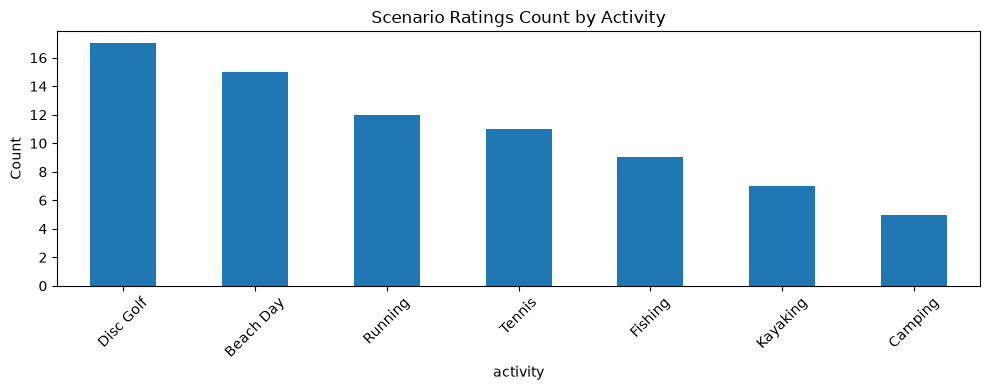

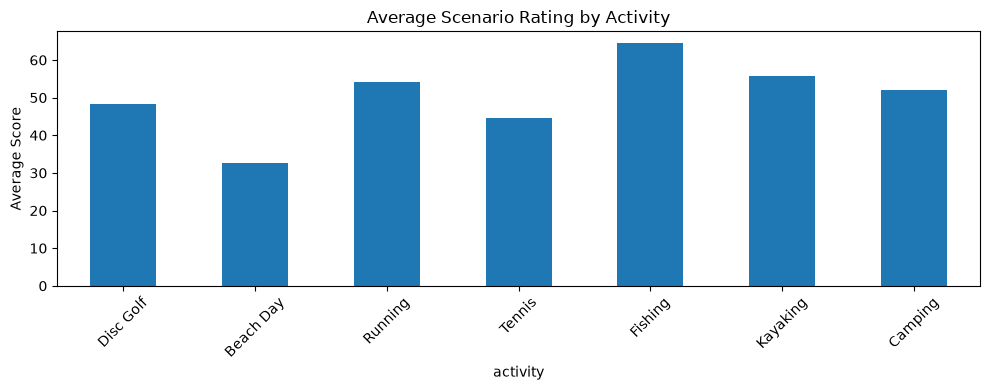

In [6]:
activity_summary["count"].plot(kind="bar", figsize=(10, 4))
plt.title("Scenario Ratings Count by Activity")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

activity_summary["average_score"].plot(kind="bar", figsize=(10, 4))
plt.title("Average Scenario Rating by Activity")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
candidate_numeric_features = [
    "temperature",
    "wind_speed",
    "wind_gust",
    "rain_chance",
    "humidity",
    "cloud_cover",
    "pressure_change",
    "bug_index",
    "water_temp",
    "storm_safety",
    "dew_point",
    "aqi",
    "uv_index",
]

candidate_categorical_features = [
    "activity",
]

numeric_features = [
    column for column in candidate_numeric_features
    if column in df_clean.columns
]

categorical_features = [
    column for column in candidate_categorical_features
    if column in df_clean.columns
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['temperature', 'wind_speed', 'wind_gust', 'rain_chance', 'humidity', 'cloud_cover', 'pressure_change', 'bug_index', 'water_temp', 'storm_safety', 'dew_point', 'aqi', 'uv_index']
Categorical features: ['activity']


In [8]:
feature_columns = numeric_features + categorical_features

model_df = df_clean[feature_columns + ["target_score"]].copy()

X = model_df[feature_columns]
y = model_df["target_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (76, 14)
y shape: (76,)


,temperature,wind_speed,wind_gust,rain_chance,humidity,cloud_cover,pressure_change,bug_index,water_temp,storm_safety,dew_point,aqi,uv_index,activity
0,51.0,22.1,NaN,36.0,NaN,47.0,NaN,NaN,NaN,55,63.6,90.0,NaN,Running
1,86.6,23.9,NaN,65.0,NaN,82.0,NaN,NaN,80.3,38,NaN,NaN,7.3,Beach Day
2,56.3,6.2,NaN,26.0,NaN,NaN,-5.8,68.0,47.7,60,NaN,NaN,NaN,Fishing
3,85.2,11.3,NaN,35.0,NaN,10.0,NaN,NaN,37.4,89,NaN,NaN,3.7,Beach Day
4,40.1,2.5,NaN,9.0,NaN,13.0,NaN,NaN,NaN,44,NaN,NaN,NaN,Tennis


In [9]:
activity_means = df_clean.groupby("activity")["target_score"].mean()
global_mean = df_clean["target_score"].mean()

baseline_predictions = df_clean["activity"].map(activity_means).fillna(global_mean)

baseline_mae = mean_absolute_error(df_clean["target_score"], baseline_predictions)

print("Activity-average baseline MAE:", round(baseline_mae, 2))
print("Global average score:", round(global_mean, 2))

Activity-average baseline MAE: 17.97
Global average score: 48.42


In [10]:
if len(df_clean) < 30:
    print("Dataset is very small. Results will be unstable.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 57
Test rows: 19


In [11]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

In [12]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0)),
    ]
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge MAE:", round(ridge_mae, 2))
print("Ridge R2:", round(ridge_r2, 3))

Ridge MAE: 17.52
Ridge R2: 0.163


In [13]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            min_samples_leaf=3,
        )),
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest R2:", round(rf_r2, 3))

Random Forest MAE: 15.27
Random Forest R2: 0.208


In [14]:
comparison = X_test.copy()
comparison["actual"] = y_test.values
comparison["ridge_prediction"] = ridge_predictions
comparison["rf_prediction"] = rf_predictions
comparison["rf_error"] = comparison["rf_prediction"] - comparison["actual"]
comparison["rf_abs_error"] = comparison["rf_error"].abs()

display(
    comparison
    .sort_values("rf_abs_error", ascending=False)
    .head(15)
)

,temperature,wind_speed,wind_gust,rain_chance,humidity,cloud_cover,pressure_change,bug_index,water_temp,storm_safety,dew_point,aqi,uv_index,activity,actual,ridge_prediction,rf_prediction,rf_error,rf_abs_error
9,81.4,2.3,NaN,3.0,NaN,97.0,NaN,NaN,NaN,41,NaN,NaN,NaN,Tennis,80,52.285428,39.575141,-40.424859,40.424859
4,40.1,2.5,NaN,9.0,NaN,13.0,NaN,NaN,NaN,44,NaN,NaN,NaN,Tennis,70,33.322601,30.256735,-39.743265,39.743265
18,31.4,8.7,17.7,NaN,81.0,100.0,0.0,30.0,NaN,90,26.2,NaN,NaN,Running,60,47.257892,28.947915,-31.052085,31.052085
10,53.5,11.2,NaN,61.0,NaN,NaN,-9.9,86.0,58.2,80,NaN,NaN,NaN,Fishing,80,96.565231,51.312540,-28.687460,28.687460
5,26.1,6.2,NaN,91.0,NaN,96.0,NaN,NaN,NaN,98,NaN,NaN,NaN,Tennis,10,44.917189,34.269414,24.269414,24.269414
53,71.5,16.6,NaN,90.0,NaN,26.0,NaN,NaN,NaN,93,NaN,NaN,NaN,Tennis,20,41.670835,43.757996,23.757996,23.757996
12,59.4,4.6,8.1,NaN,88.0,24.0,0.0,53.0,NaN,90,55.9,NaN,NaN,Fishing,50,57.806217,67.611688,17.611688,17.611688
65,69.7,8.5,26.6,NaN,82.0,100.0,0.0,70.0,NaN,90,63.9,NaN,NaN,Disc Golf,80,53.350840,64.674461,-15.325539,15.325539
34,77.7,2.8,11.2,NaN,26.0,0.0,0.0,80.0,NaN,90,40.2,NaN,NaN,Running,50,78.934546,62.585826,12.585826,12.585826
67,40.6,13.4,31.3,NaN,31.0,0.0,0.0,10.0,NaN,90,12.2,NaN,NaN,Beach Day,20,28.028773,32.038077,12.038077,12.038077


In [15]:
if len(df_clean) >= 30:
    cv_folds = min(5, len(df_clean))

    rf_cv_scores = cross_val_score(
        rf_model,
        X,
        y,
        cv=cv_folds,
        scoring="neg_mean_absolute_error",
    )

    ridge_cv_scores = cross_val_score(
        ridge_model,
        X,
        y,
        cv=cv_folds,
        scoring="neg_mean_absolute_error",
    )

    print("Random Forest CV MAE scores:", np.round(-rf_cv_scores, 2))
    print("Random Forest CV MAE average:", round(-rf_cv_scores.mean(), 2))

    print("Ridge CV MAE scores:", np.round(-ridge_cv_scores, 2))
    print("Ridge CV MAE average:", round(-ridge_cv_scores.mean(), 2))
else:
    print("Not enough rows for useful cross-validation.")

Random Forest CV MAE scores: [18.59 20.91 13.82 13.8  16.97]
Random Forest CV MAE average: 16.82
Ridge CV MAE scores: [28.99 17.05 16.88 17.33 19.62]
Ridge CV MAE average: 19.97


,feature,importance
0,temperature,0.364847
4,humidity,0.107975
9,storm_safety,0.097721
10,dew_point,0.078615
2,wind_gust,0.067718
1,wind_speed,0.063404
7,bug_index,0.058891
3,rain_chance,0.057868
5,cloud_cover,0.055855
16,activity_Fishing,0.013809


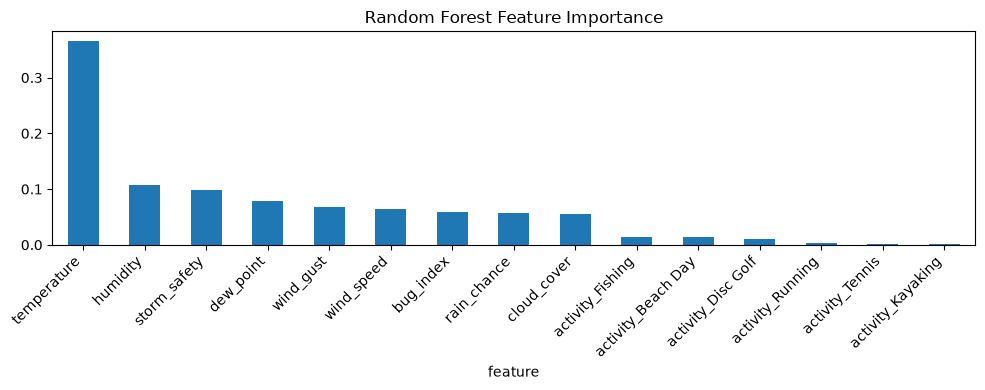

In [16]:
trained_preprocessor = rf_model.named_steps["preprocessor"]
trained_rf = rf_model.named_steps["model"]

feature_names = []

if numeric_features:
    feature_names.extend(numeric_features)

if categorical_features:
    onehot = trained_preprocessor.named_transformers_["cat"].named_steps["onehot"]
    categorical_names = onehot.get_feature_names_out(categorical_features)
    feature_names.extend(categorical_names)

importances = trained_rf.feature_importances_

importance_df = pd.DataFrame(
    {
        "feature": feature_names,
        "importance": importances,
    }
).sort_values("importance", ascending=False)

display(importance_df.head(20))

importance_df.head(15).plot(
    x="feature",
    y="importance",
    kind="bar",
    figsize=(10, 4),
    legend=False,
)

plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:
test_results = X_test.copy()
test_results["actual"] = y_test.values
test_results["prediction"] = rf_predictions
test_results["abs_error"] = (test_results["prediction"] - test_results["actual"]).abs()

error_by_activity = (
    test_results
    .groupby("activity")
    .agg(
        count=("abs_error", "count"),
        mean_abs_error=("abs_error", "mean"),
        avg_actual=("actual", "mean"),
        avg_prediction=("prediction", "mean"),
    )
    .round(2)
    .sort_values("mean_abs_error", ascending=False)
)

display(error_by_activity)

,count,mean_abs_error,avg_actual,avg_prediction
activity,,,,
Tennis,4,32.05,45.00,36.96
Fishing,3,18.15,70.00,63.59
Running,5,11.02,52.00,49.77
Disc Golf,3,9.70,73.33,63.63
Beach Day,2,8.72,30.00,38.72
Camping,1,5.31,70.00,64.69
Kayaking,1,0.50,70.00,70.50


In [18]:
advanced_columns = [
    column for column in df_clean.columns
    if column.startswith("advanced_") or column.startswith("location_")
]

print("Advanced/location columns found:", len(advanced_columns))

for column in advanced_columns[:50]:
    print(column)

Advanced/location columns found: 35
advanced_month
advanced_season
advanced_flow_trend
advanced_moon_phase
advanced_visibility
advanced_fire_danger
advanced_rain_amount
advanced_gauge_height
advanced_pollen_index
advanced_overnight_low
advanced_daylight_hours
advanced_river_flow_cfs
advanced_wave_height_ft
advanced_wind_direction
advanced_recent_rain_24h
advanced_recent_rain_72h
advanced_rip_current_risk
advanced_moon_illumination
advanced_water_quality_alert
location_latitude
location_longitude
location_location_query
location_selected_saved_location_label
location_notes
location_water_type
location_usgs_site_id
location_location_name
location_location_type
location_use_ndbc_data
location_wind_exposure
location_ndbc_station_id
location_water_body_size
location_manual_water_temp
location_saved_location_id
location_use_usgs_water_data


In [19]:
print("=== ML Exploration Summary ===")
print(f"Rows: {len(df_clean)}")
print(f"Activities: {df_clean['activity'].nunique()}")
print(f"Activity-average baseline MAE: {baseline_mae:.2f}")

try:
    print(f"Ridge test MAE: {ridge_mae:.2f}")
    print(f"Random Forest test MAE: {rf_mae:.2f}")
except NameError:
    pass

print("\nRecommended next data goals:")
print("- Aim for at least 25 ratings per activity.")
print("- Then aim for 50+ ratings per activity.")
print("- Keep using rule-based scoring until ML beats activity-average baseline reliably.")

=== ML Exploration Summary ===
Rows: 76
Activities: 7
Activity-average baseline MAE: 17.97
Ridge test MAE: 17.52
Random Forest test MAE: 15.27

Recommended next data goals:
- Aim for at least 25 ratings per activity.
- Then aim for 50+ ratings per activity.
- Keep using rule-based scoring until ML beats activity-average baseline reliably.
